In [1]:
#importing libraries
import sys
sys.path.append("..")

import json
import joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import PROCESSED_DIR
from src.preprocessing import build_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import precision_recall_curve

In [2]:
#loading train data and patient ids
X_train = pd.read_parquet(PROCESSED_DIR / "X_train.parquet")
y_train = pd.read_parquet(PROCESSED_DIR / "y_train.parquet")["readmitted_30"]
groups_train = pd.read_parquet(PROCESSED_DIR / "groups_train.parquet")["patient_nbr"]
print(X_train.shape, y_train.shape)

(69613, 44) (69613,)


In [3]:
#defining random forest and gradient boosting
models = {
    "Random Forest": Pipeline([
        ("pre", build_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced",
                                         n_jobs=-1, random_state=42)),
    ]),
    "Gradient Boosting": Pipeline([
        ("pre", build_preprocessor()),
        ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    ]),
}

In [4]:
#setting up 5 grouped folds
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

In [5]:
#cross validating both models
rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, groups=groups_train, cv=cv, scoring="average_precision", n_jobs=-1)
    rows.append({"model": name, "pr_auc": s["test_score"].mean(), "pr_auc_std": s["test_score"].std(ddof=1),
                 "fit_seconds": s["fit_time"].mean()})
    print(name, "PR-AUC:", round(s["test_score"].mean(), 4))

Random Forest PR-AUC: 0.219


Gradient Boosting PR-AUC: 0.2191


In [6]:
#comparing with the baseline from notebook 04
baseline = json.load(open("../reports/baseline_results.json"))
comparison = pd.DataFrame(rows).round(4)
print("baseline logistic regression:", baseline["cv_pr_auc"])
comparison

baseline logistic regression: 0.2129


,model,pr_auc,pr_auc_std,fit_seconds
0,Random Forest,0.2190,0.0052,21.5068
1,Gradient Boosting,0.2191,0.0068,5.3725


In [7]:
#tuning random forest
rf_grid = {
    "model__min_samples_leaf": [5, 10, 20],
    "model__max_features": ["sqrt", 0.3],
}
rf_search = GridSearchCV(models["Random Forest"], rf_grid, scoring="average_precision", cv=cv, n_jobs=2)
rf_search.fit(X_train, y_train, groups=groups_train)
print(rf_search.best_params_, round(rf_search.best_score_, 4))

{'model__max_features': 0.3, 'model__min_samples_leaf': 10} 0.2264


In [8]:
#tuning gradient boosting
gb_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31],
    "model__min_samples_leaf": [20, 100],
}
gb_search = GridSearchCV(models["Gradient Boosting"], gb_grid, scoring="average_precision", cv=cv, n_jobs=-1)
gb_search.fit(X_train, y_train, groups=groups_train)
print(gb_search.best_params_, round(gb_search.best_score_, 4))

{'model__learning_rate': 0.1, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 20} 0.2228


In [9]:
#comparing tuned models with baseline
print("baseline logistic regression:", baseline["cv_pr_auc"])
print("tuned random forest:", round(rf_search.best_score_, 4))
print("tuned gradient boosting:", round(gb_search.best_score_, 4))

baseline logistic regression: 0.2129
tuned random forest: 0.2264
tuned gradient boosting: 0.2228


In [10]:
#picking random forest as final model
best_model = rf_search.best_estimator_
best_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](44,)","['race','gender','age',...,'metformin-pioglitazone','change','diabetesMed']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,44
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('encode', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Us

In [11]:
#out of fold probabilities of the final model
proba = cross_val_predict(best_model, X_train, y_train, groups=groups_train, cv=cv, method="predict_proba", n_jobs=2)[:, 1]
proba[:10].round(3)

array([0.267, 0.38 , 0.39 , 0.324, 0.299, 0.326, 0.241, 0.437, 0.353,
       0.404])

In [12]:
#finding the best threshold by f1
precision, recall, thresholds = precision_recall_curve(y_train, proba)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_i = np.argmax(f1[:-1])
threshold = float(thresholds[best_i])
print("best threshold:", round(threshold, 3))
print("precision:", round(precision[best_i], 3), "recall:", round(recall[best_i], 3), "f1:", round(f1[best_i], 3))

best threshold: 0.486
precision: 0.211 recall: 0.434 f1: 0.284


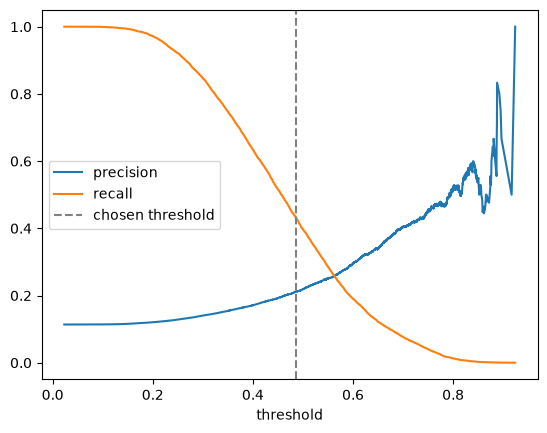

In [13]:
#precision and recall vs threshold
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.axvline(threshold, ls="--", color="gray", label="chosen threshold")
plt.xlabel("threshold"); plt.legend()
plt.show()

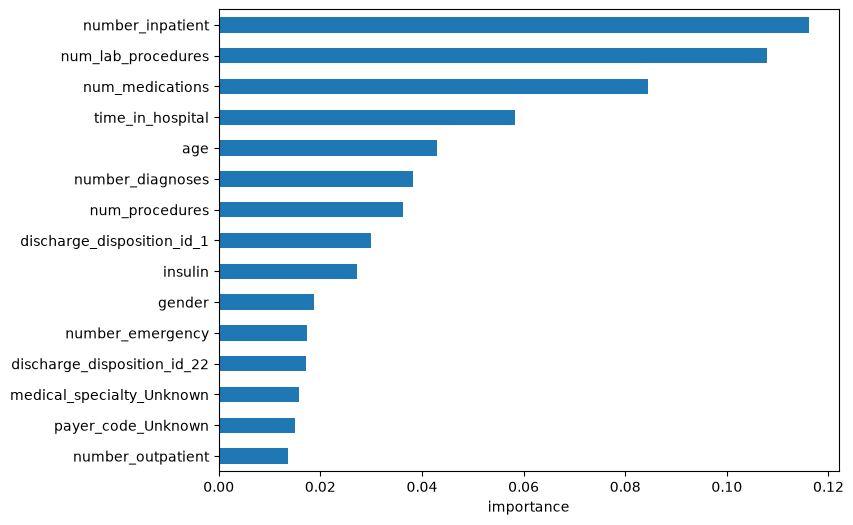

In [14]:
#top 15 important features
importance = pd.Series(best_model["model"].feature_importances_, index=best_model["model"].feature_names_in_)
importance.sort_values().tail(15).plot(kind="barh", figsize=(8, 6))
plt.xlabel("importance")
plt.show()

In [15]:
#saving model, threshold and results
Path("../models").mkdir(exist_ok=True)
joblib.dump(best_model, "../models/final_model.joblib")

selection_results = {
    "final_model": "Random Forest",
    "best_params": rf_search.best_params_,
    "cv_pr_auc": round(float(rf_search.best_score_), 4),
    "threshold": round(threshold, 4),
    "comparison": comparison.set_index("model")["pr_auc"].to_dict(),
    "tuned_random_forest": round(float(rf_search.best_score_), 4),
    "tuned_gradient_boosting": round(float(gb_search.best_score_), 4),
}
json.dump(selection_results, open("../reports/model_selection_results.json", "w"), indent=2)
selection_results

{'final_model': 'Random Forest',
 'best_params': {'model__max_features': 0.3, 'model__min_samples_leaf': 10},
 'cv_pr_auc': 0.2264,
 'threshold': 0.4855,
 'comparison': {'Random Forest': 0.219, 'Gradient Boosting': 0.2191},
 'tuned_random_forest': 0.2264,
 'tuned_gradient_boosting': 0.2228}